## Step 1: Imports
Load Python libraries used for data processing, modeling, and visualization.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

## Step 2: Load Source Data
Read the merged market history dataset used for forecasting.

In [3]:
# df_grouped = pd.read_csv("grouped_price_history_data_forecasting_model.csv")
df_merged = pd.read_csv("merged_price_history_data_forecasting_model.csv")

## Step 3: Filter to Yes Outcome
Keep the Yes-side market probabilities for the modeling. 

In [4]:
df_merged_yes = df_merged[df_merged['outcome'] == 'Yes']

df_merged_yes

,t,p,market_id,event_name,outcome,category
0,1774114257,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,Yes,Politics
1,1774114846,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,Yes,Politics
2,1774115445,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,Yes,Politics
3,1774116052,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,Yes,Politics
4,1774116639,0.5550,2916184120206223749839849644877707470354946028...,US forces enter Iran by April 30?,Yes,Politics
...,...,...,...,...,...,...
230744,1775352050,0.9995,4181791186660365497672402528416011986301733749...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
230745,1775353249,0.9995,4181791186660365497672402528416011986301733749...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
230746,1775353847,0.9995,4181791186660365497672402528416011986301733749...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
230747,1775355049,0.9995,4181791186660365497672402528416011986301733749...,Will FC Barcelona win on 2026-04-04?,Yes,Sports


## Step 4: Build 30-Minute Modeling Table
Resample each event time series to 30-minute intervals to smooth the data - this helps reduce any noise and allows us to focus on long term patterns.

In [5]:
# Create a copy of the un-grouped merged data using df_merged_yes
df_resample = df_merged_yes.copy()

# Ensure datetime is set and set it as the index for resampling
df_resample['datetime'] = pd.to_datetime(df_resample['t'], unit='s')
df_resample.set_index('datetime', inplace=True)

# Group by our keys and resample to 30-minute intervals, taking the mean of the prices
df_30m = df_resample.groupby(['event_name', 'category', 'outcome']).resample('30min')['p'].mean().reset_index()

# Drop intervals that had no data (NaNs)
df_30m = df_30m.dropna(subset=['p'])

# Convert datetime back to Unix timestamps for consistency
# Using a map to safely process the datetime to a unix seconds timestamp
df_30m['t'] = df_30m['datetime'].apply(lambda x: int(x.timestamp()))


df_30m = df_30m.rename(columns={
    'event_name': 'Event_name',
    't': 'timestamp',
    'p': 'price'
})

print(f"Total records after 30-minute resampling: {len(df_30m)}")
display(df_30m.head(10))

Total records after 30-minute resampling: 42997


,Event_name,category,outcome,datetime,price,timestamp
0,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 21:30:00,0.530000,1774819800
1,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:00:00,0.570000,1774821600
2,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:30:00,0.485000,1774823400
3,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:00:00,0.485000,1774825200
4,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:30:00,0.453333,1774827000
5,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:00:00,0.485000,1774828800
6,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:30:00,0.485000,1774830600
7,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:00:00,0.485000,1774832400
8,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:30:00,0.485000,1774834200
9,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 02:00:00,0.485000,1774836000


## Step 5: Visualize Event Probability Paths
Plot probability trajectories over time to inspect trends and variability across events.

/tmp/ipykernel_4072739/509940459.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


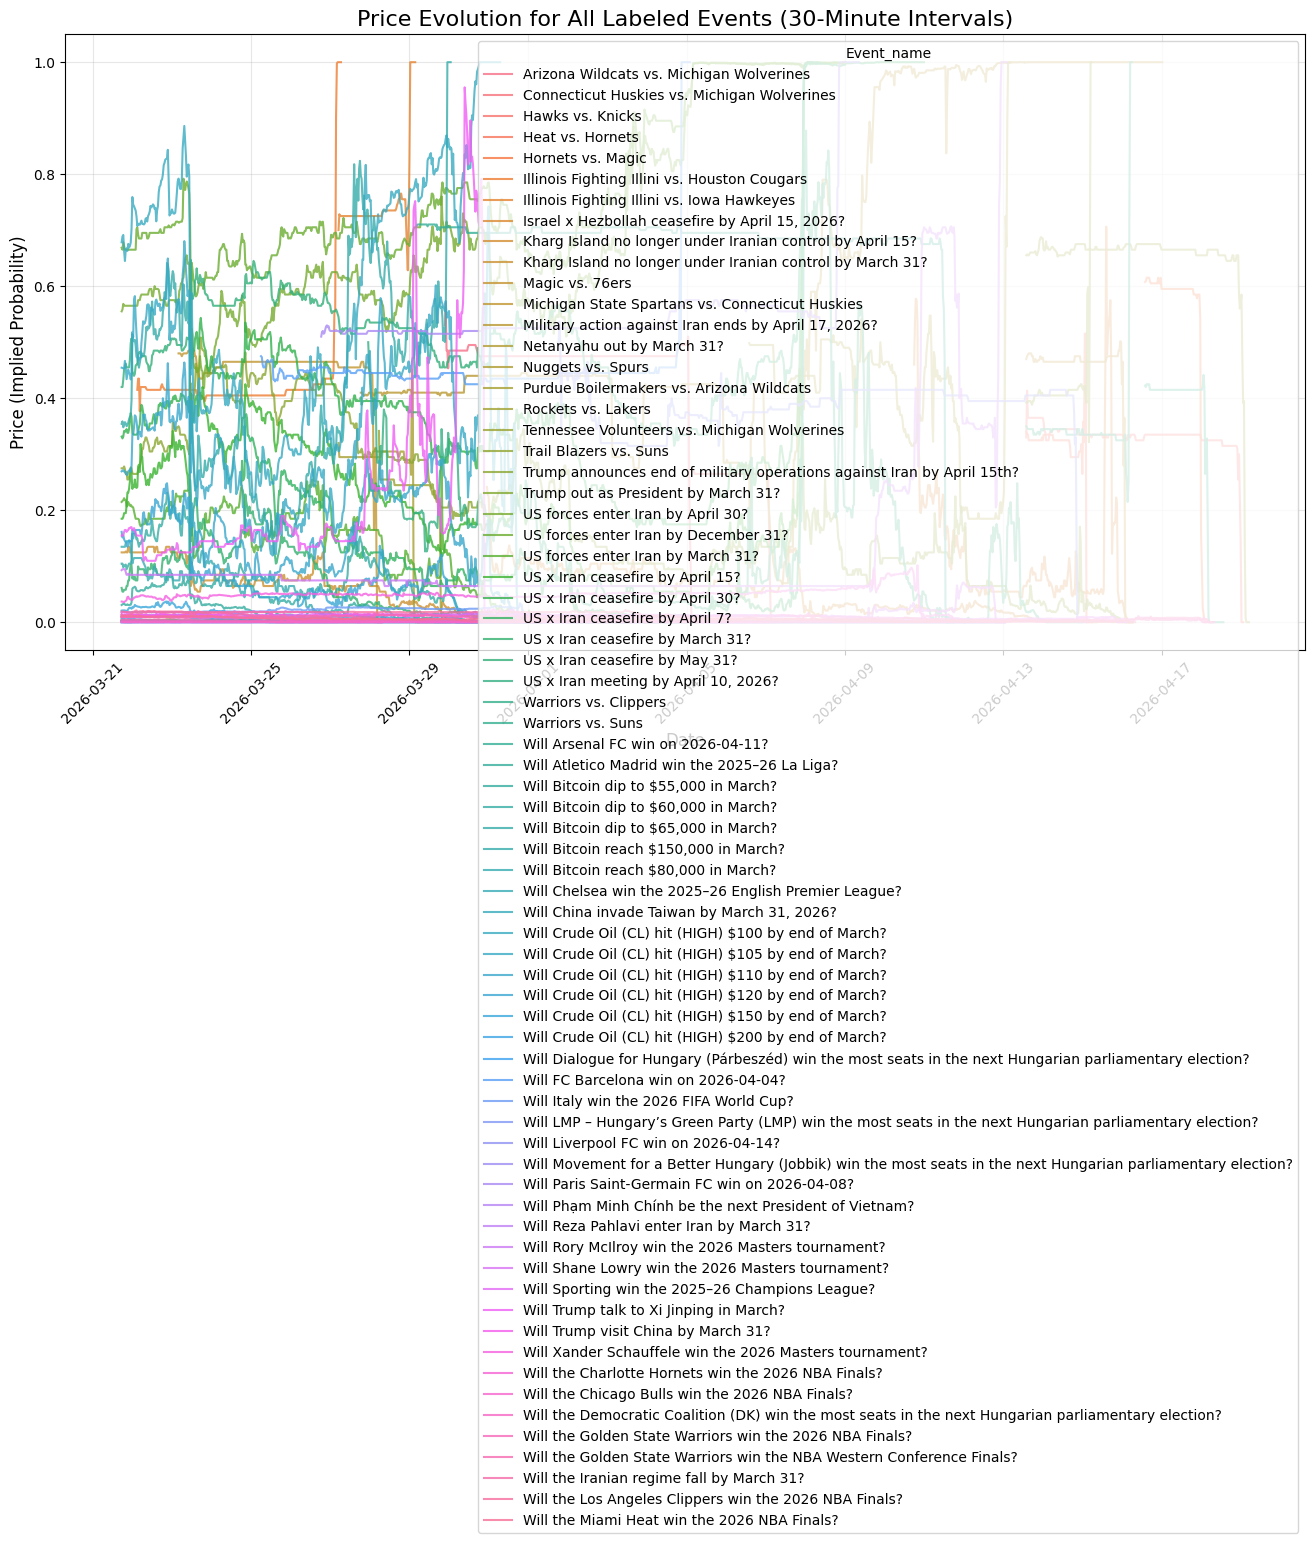

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

# Plot each event's price over time
sns.lineplot(data=df_30m, x='datetime', y='price', hue='Event_name', alpha=0.8, linewidth=1.5)

plt.title('Price Evolution for All Labeled Events (30-Minute Intervals)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (Implied Probability)', fontsize=12)

# # Place the legend outside the plot area to avoid cluttering if there are many events
# if df_30m['Event_name'].nunique() > 10:
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', title='Event Name')
# else:
#     plt.legend(title='Event Name')

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Forecasting Objective and Approach

**Research Question:** Given an event and its history of prediction probabilities, what will its prediction probability be **X days from now**?

In this notebook, we operationalize that question with lag features and rolling statistics from each event's past trajectory, then train an XGBoost regressor with a temporal (non-shuffled) train/test split.

How this maps to the research question:
- Each row uses only past information for that event.
- The model predicts a future probability at a chosen horizon.
- We evaluate with RMSE/MAE and visualize autoregressive multi-step forecasts.

Current implementation detail:
- The demonstrated horizon is 8 future 30-minute steps (4 hours), which is a short-horizon prototype of the broader **X-day** forecasting objective.
- The same framework can be extended by increasing forecast steps to match the desired X-day horizon.

Creating 8 lag features (4 hours total)...
Training shapes: X=(33949, 14), y=(33949,)
Testing shapes: X=(8488, 14), y=(8488,)
Training XGBoost Regressor...

--- Model Evaluation ---
RMSE: 0.0010
MAE:  0.0004

--- Top 10 Feature Importances ---


,Feature,Importance
4,price_lag_1,0.986644
9,price_lag_6,0.001616
6,price_lag_3,0.001530
8,price_lag_5,0.001314
5,price_lag_2,0.001304
7,price_lag_4,0.001264
3,category_Sports,0.001191
12,rolling_mean_4h,0.000986
10,price_lag_7,0.000881
11,price_lag_8,0.000768


/tmp/ipykernel_4072739/3925557980.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')


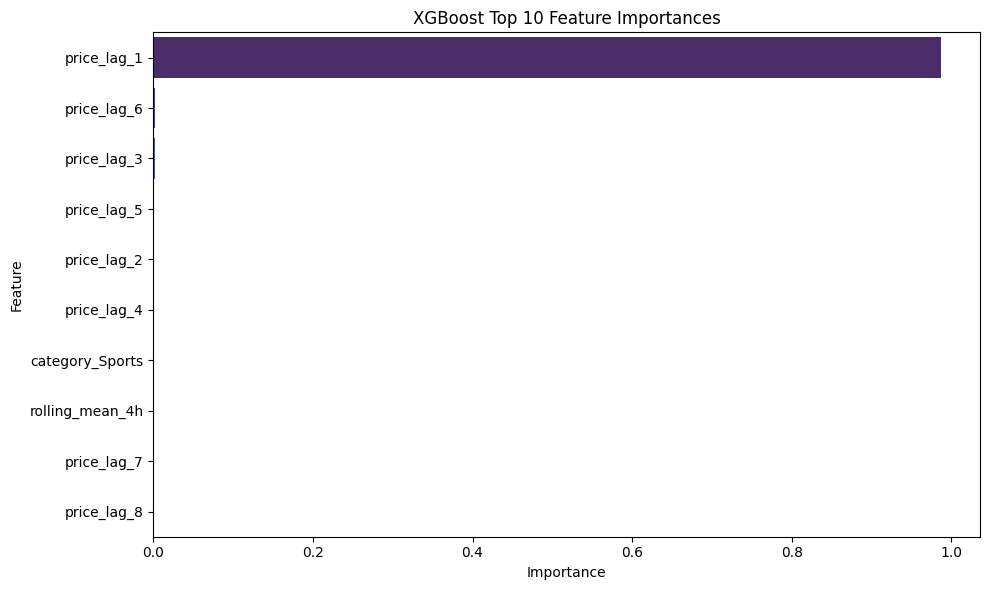

In [7]:
# !pip install xgboost scikit-learn

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Prepare copy of data and sort chronologically per event
df_ml = df_30m.copy()
df_ml = df_ml.sort_values(by=['Event_name', 'datetime'])

# 2. Encode the category column using One-Hot Encoding
df_ml = pd.get_dummies(df_ml, columns=['category'], drop_first=False)

# 3. Create 4-hour sliding window features 
# Since data is in 30-min intervals, 4 hours = 8 intervals
window_size = 8

print(f"Creating {window_size} lag features (4 hours total)...")
for i in range(1, window_size + 1):
    df_ml[f'price_lag_{i}'] = df_ml.groupby('Event_name')['price'].shift(i)

# Add rolling window statistics (mean and std) over the preceding 4 hours
df_ml['rolling_mean_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).mean()
)
df_ml['rolling_std_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).std()
)

# Drop rows with NaN values resulting from the shift (the first 4 hours of each event)
df_ml = df_ml.dropna().reset_index(drop=True)

# 4. Separate Features (X) and Target (y)
# Target is the current price. We predict it using the 4 hours of past prices.
exclude_cols = ['Event_name', 'outcome', 'timestamp', 'datetime', 't', 'price']
feature_cols = [c for c in df_ml.columns if c not in exclude_cols]

X = df_ml[feature_cols]
y = df_ml['price']

# 5. Temporal Train/Test Split (80/20)
# We avoid random shuffling to prevent data leakage from the future into the past
split_idx = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Testing shapes: X={X_test.shape}, y={y_test.shape}")

# 6. Train XGBoost Regressor
# Values are bounded 0-1, so we could use a logistic objective or clip predictions
model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective='reg:squarederror'
)

print("Training XGBoost Regressor...")
model.fit(X_train, y_train)

# 7. Evaluate Model
preds = model.predict(X_test)
preds = np.clip(preds, 0, 1)  # Ensure probabilities stay between 0 and 1

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)

print("\n--- Model Evaluation ---")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

# 8. Feature Importances
importance = pd.DataFrame({
    'Feature': feature_cols, 
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 10 Feature Importances ---")
display(importance.head(10))

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Top 10 Feature Importances")
plt.tight_layout()
plt.show()

## Step 7: Multi-Step Autoregressive Forecast Check
Run recursive forecasts and compare predicted vs true paths over the selected forecast horizon (short-horizon prototype for the broader X-day objective).

[(0.0945, 'Will Xander Schauffele win the 2026 Masters tournament?', 203), (0.008, 'Will the Golden State Warriors win the 2026 NBA Finals?', 1202), (0.006999999999999999, 'Will the Charlotte Hornets win the 2026 NBA Finals?', 1294), (0.005500000000000001, 'Will the Golden State Warriors win the NBA Western Conference Finals?', 1301), (0.005333333333333334, 'Will the Iranian regime fall by March 31?', 78), (0.004666666666666667, 'Will the Los Angeles Clippers win the 2026 NBA Finals?', 821), (0.0026666666666666666, 'Will the Miami Heat win the 2026 NBA Finals?', 1154), (0.0010000000000000002, 'Will the Chicago Bulls win the 2026 NBA Finals?', 172), (0.000375, 'Will the Democratic Coalition (DK) win the most seats in the next Hungarian parliamentary election?', 441)]

Top 1 Event (Highest Min-Max Deviation: 0.0945): Will Xander Schauffele win the 2026 Masters tournament?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0376
MAE (Mean Absolute Error):      0.0327
Direct

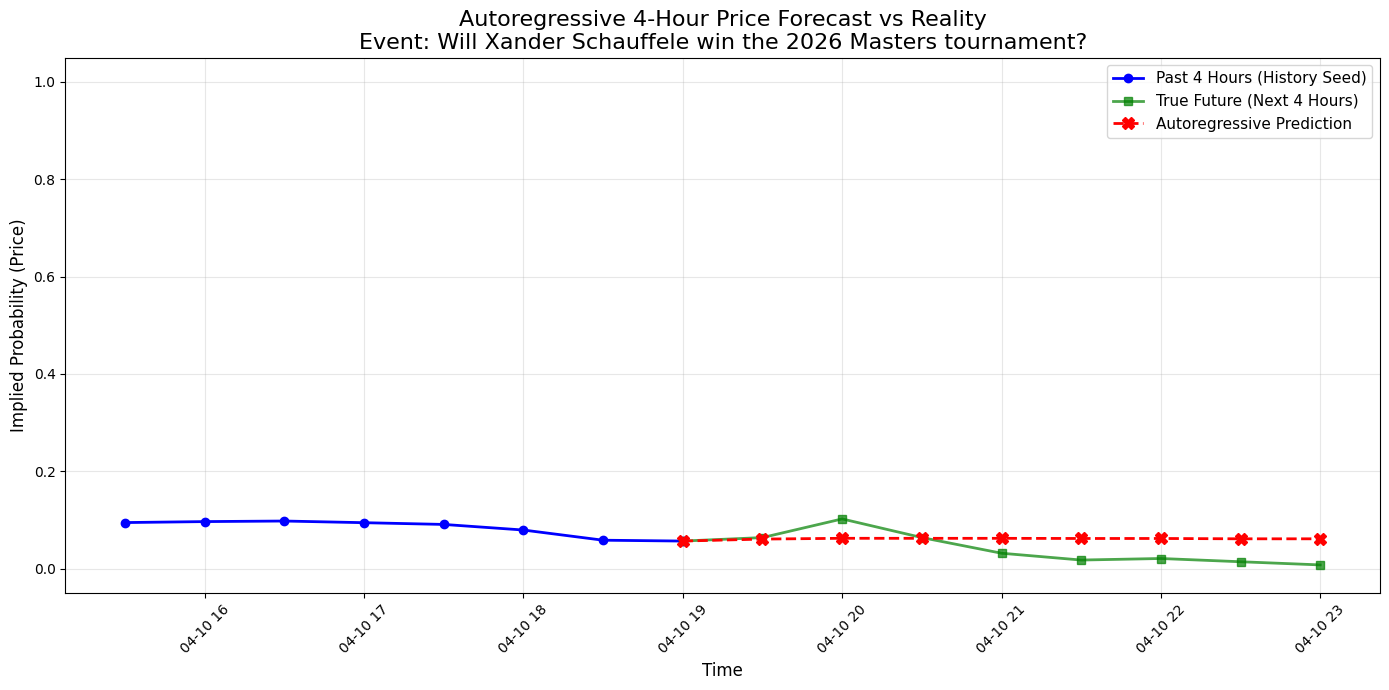


Top 2 Event (Highest Min-Max Deviation: 0.0080): Will the Golden State Warriors win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0039
MAE (Mean Absolute Error):      0.0030
Directional Accuracy:           37.5%



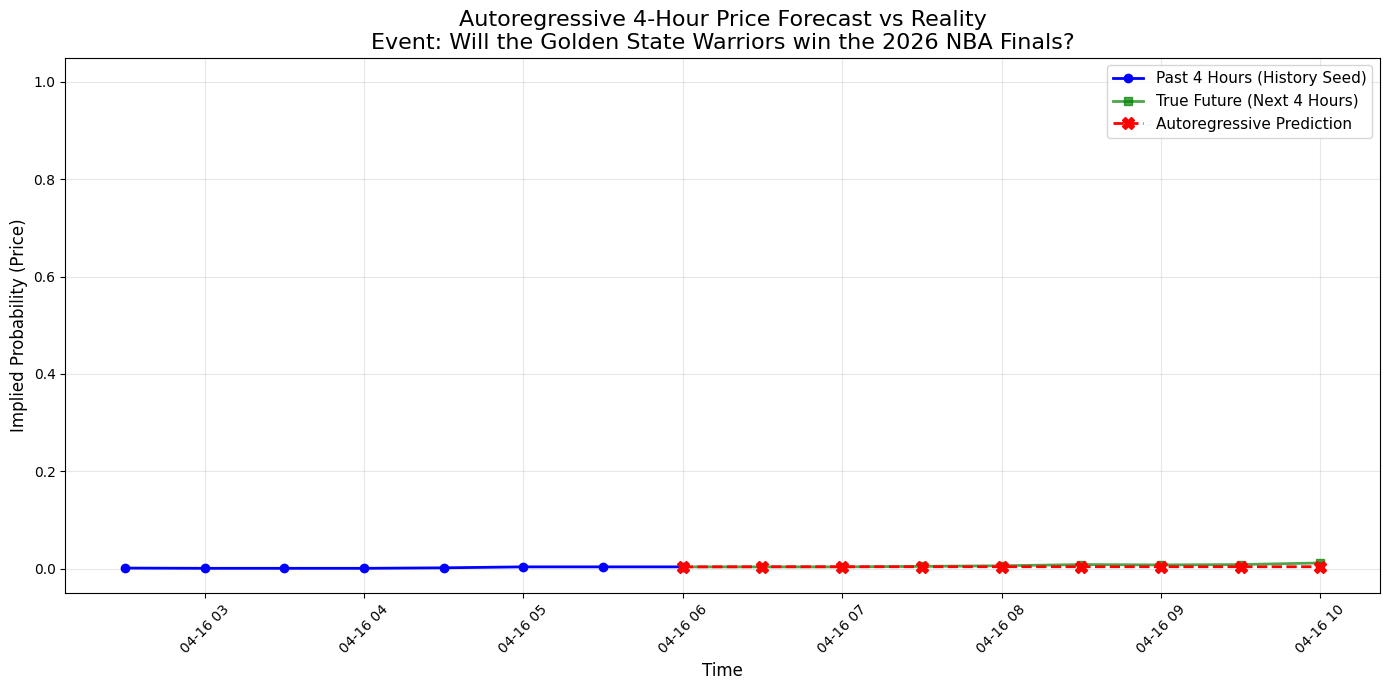


Top 3 Event (Highest Min-Max Deviation: 0.0070): Will the Charlotte Hornets win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0026
MAE (Mean Absolute Error):      0.0020
Directional Accuracy:           75.0%



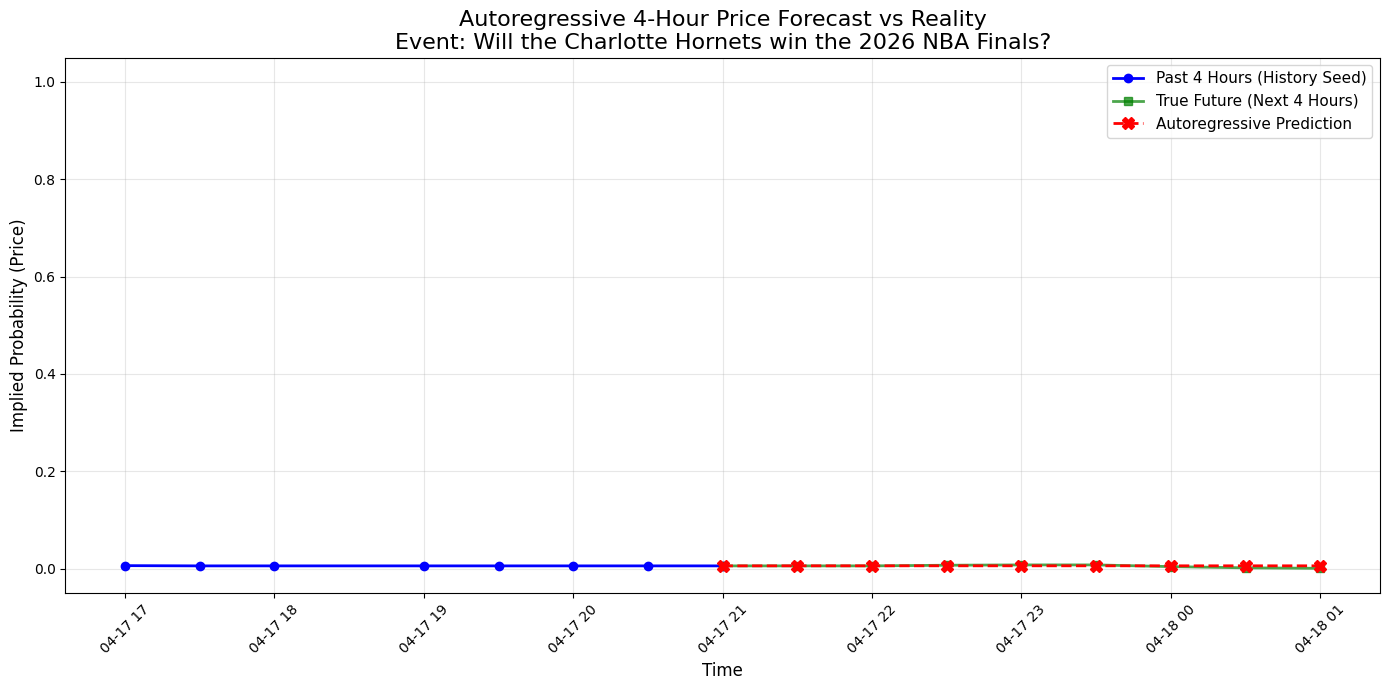


Top 4 Event (Highest Min-Max Deviation: 0.0055): Will the Golden State Warriors win the NBA Western Conference Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0029
MAE (Mean Absolute Error):      0.0018
Directional Accuracy:           62.5%



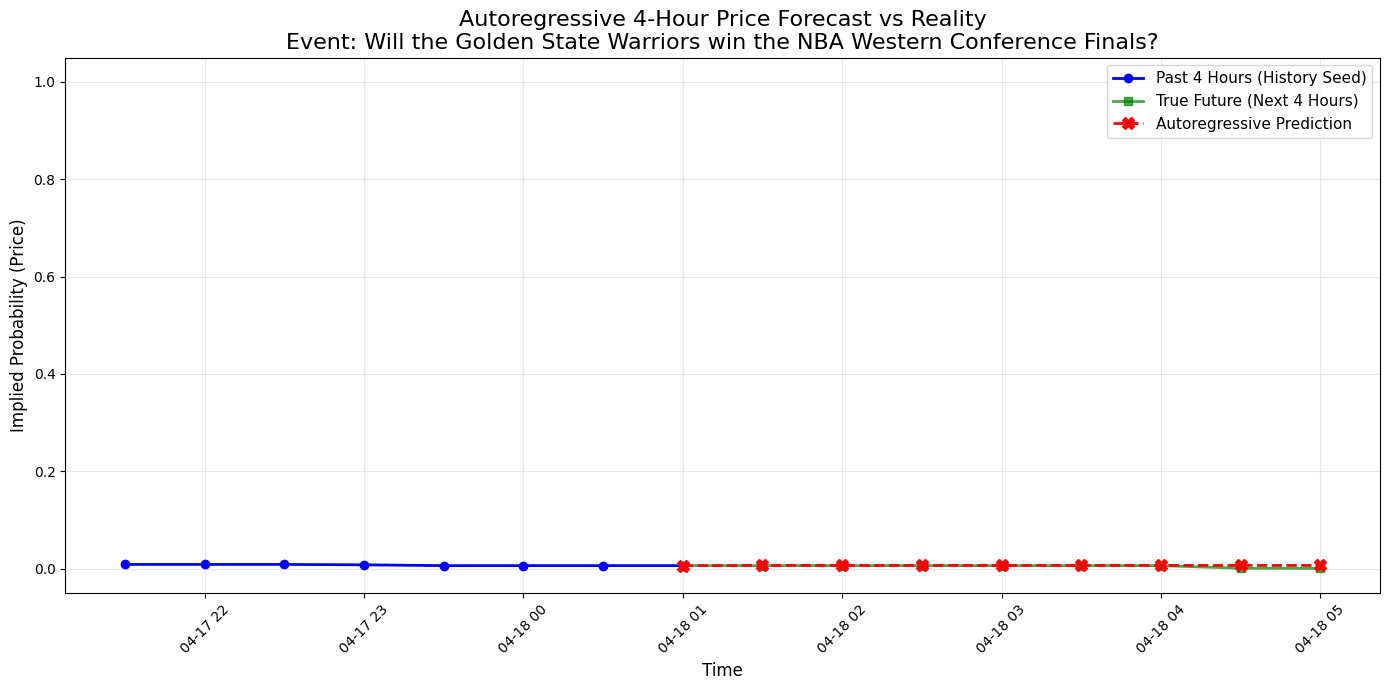


Top 5 Event (Highest Min-Max Deviation: 0.0053): Will the Iranian regime fall by March 31?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0020
MAE (Mean Absolute Error):      0.0014
Directional Accuracy:           25.0%



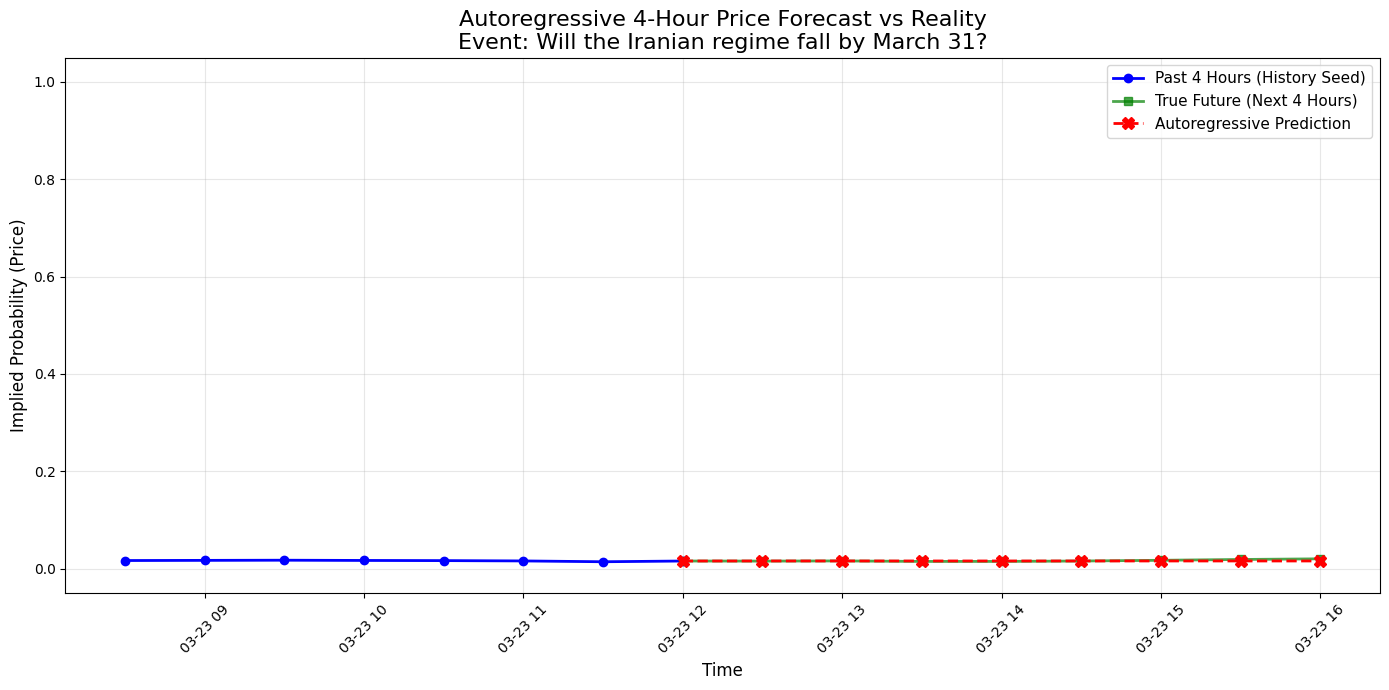

In [8]:
# 1. Select a valid event from the test set that has at least 8 remaining steps
test_df = df_ml.iloc[split_idx:].copy()
valid_events = test_df['Event_name'].value_counts()
valid_events = valid_events[valid_events >= 8].index

# Find sequences with the highest min-max deviation in their 8-step forward window for each event
event_max_deviations = []

for event in valid_events:
    event_data = test_df[test_df['Event_name'] == event].reset_index()
    max_deviation = -1
    best_start_idx = 0
    for i in range(len(event_data) - 7):  # Ensure there are 8 remaining steps
        future_window = event_data.iloc[i : i + 8]['price']
        deviation = future_window.max() - future_window.min()
        if deviation > max_deviation:
            max_deviation = deviation
            best_start_idx = i
    if max_deviation >= 0:
        event_max_deviations.append((max_deviation, event, best_start_idx))

# Sort descending and get top 5
event_max_deviations.sort(reverse=True, key=lambda x: x[0])

print(event_max_deviations)

top_events = event_max_deviations[:5]

for rank, (dev, sample_event, best_start_idx) in enumerate(top_events, 1):
    print(f"\n{'='*50}")
    print(f"Top {rank} Event (Highest Min-Max Deviation: {dev:.4f}): {sample_event}")
    print(f"{'='*50}\n")
    
    event_test_data = test_df[test_df['Event_name'] == sample_event].reset_index()

    # 2. Extract the initial state (the seed)
    start_row = event_test_data.iloc[best_start_idx]
    start_datetime = start_row['datetime']

    current_sequence = [start_row[f'price_lag_{i}'] for i in range(window_size, 0, -1)]
    feature_row = start_row[feature_cols].copy()
    predictions = []

    # 3. Recursive Forecasting (8 steps = 4 hours)
    for step in range(8):
        pred_df_row = pd.DataFrame([feature_row], columns=feature_cols).astype(X_train.dtypes.to_dict())
        
        pred_price = float(model.predict(pred_df_row)[0])
        pred_price = float(np.clip(pred_price, 0, 1))
        predictions.append(pred_price)
        
        current_sequence.append(pred_price)
        
        for i in range(1, window_size + 1):
            feature_row[f'price_lag_{i}'] = current_sequence[-i]
            
        feature_row['rolling_mean_4h'] = np.mean(current_sequence[-window_size:])
        feature_row['rolling_std_4h'] = np.std(current_sequence[-window_size:], ddof=1)

    # 4. Gather True Data for comparision
    df_30m_event = df_30m[df_30m['Event_name'] == sample_event].reset_index(drop=True)
    start_idx_30m = df_30m_event[df_30m_event['datetime'] == start_datetime].index[0]

    history_df = df_30m_event.iloc[start_idx_30m - window_size : start_idx_30m].copy()
    future_df = df_30m_event.iloc[start_idx_30m : start_idx_30m + 8].copy()

    pred_df = future_df.copy()
    pred_df['price'] = predictions

    last_history_time = history_df['datetime'].iloc[-1]
    last_history_price = history_df['price'].iloc[-1]

    # 5. Evaluate Forecasting Metrics
    true_future_prices = future_df['price'].values
    pred_future_prices = np.array(predictions)

    ar_rmse = np.sqrt(mean_squared_error(true_future_prices, pred_future_prices))
    ar_mae = mean_absolute_error(true_future_prices, pred_future_prices)

    true_direction = np.diff([last_history_price] + list(true_future_prices)) > 0
    pred_direction = np.diff([last_history_price] + list(pred_future_prices)) > 0
    directional_accuracy = np.mean(true_direction == pred_direction) * 100

    print("=== 4-Hour Forecast Metrics ===")
    print(f"RMSE (Root Mean Squared Error): {ar_rmse:.4f}")
    print(f"MAE (Mean Absolute Error):      {ar_mae:.4f}")
    print(f"Directional Accuracy:           {directional_accuracy:.1f}%\n")

    # 6. Plotting
    plt.figure(figsize=(14, 7))

    plt.plot(history_df['datetime'], history_df['price'], label='Past 4 Hours (History Seed)', color='blue', marker='o', linewidth=2)

    true_times = [last_history_time] + future_df['datetime'].tolist()
    true_prices = [last_history_price] + future_df['price'].tolist()
    pred_prices = [last_history_price] + pred_df['price'].tolist()

    plt.plot(true_times, true_prices, label='True Future (Next 4 Hours)', color='green', linestyle='-', marker='s', linewidth=2, alpha=0.7)
    plt.plot(true_times, pred_prices, label='Autoregressive Prediction', color='red', linestyle='--', marker='X', markersize=8, linewidth=2)

    plt.title(f'Autoregressive 4-Hour Price Forecast vs Reality\nEvent: {sample_event}', fontsize=16)
    plt.xlabel('Time', fontsize=12)
    plt.ylabel('Implied Probability (Price)', fontsize=12)
    plt.ylim(-0.05, 1.05) # Reverted to normal full percentage boundaries to see full variation
    plt.grid(alpha=0.3)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Step 8: Raw Data Window Sensitivity Test
Repeat the window-size experiment on df_resample (without 30-minute averaging) to compare error and forecast flatness.

=== Raw df_resample (irregular sampling) interval diagnostics (minutes) ===
count    115977.000000
mean         11.168341
std           4.239711
min           0.550000
50%          10.016667
90%          10.916667
95%          20.016667
max         100.050000
Name: delta_min, dtype: float64

=== Window Sensitivity on Raw df_resample (irregular sampling) ===


,window_size_points,train_rows,test_rows,feature_count,rmse,mae,pred_step_abs_change,true_step_abs_change,flatness_ratio_pred_to_true,pred_std
0,4,92613,23154,10,0.000733,0.000278,0.000102,0.000109,0.931071,0.009808
1,8,92389,23098,14,0.000691,0.000279,0.000099,0.000109,0.904429,0.009691
2,16,91941,22986,22,0.000687,0.000277,0.000101,0.000109,0.922206,0.009462


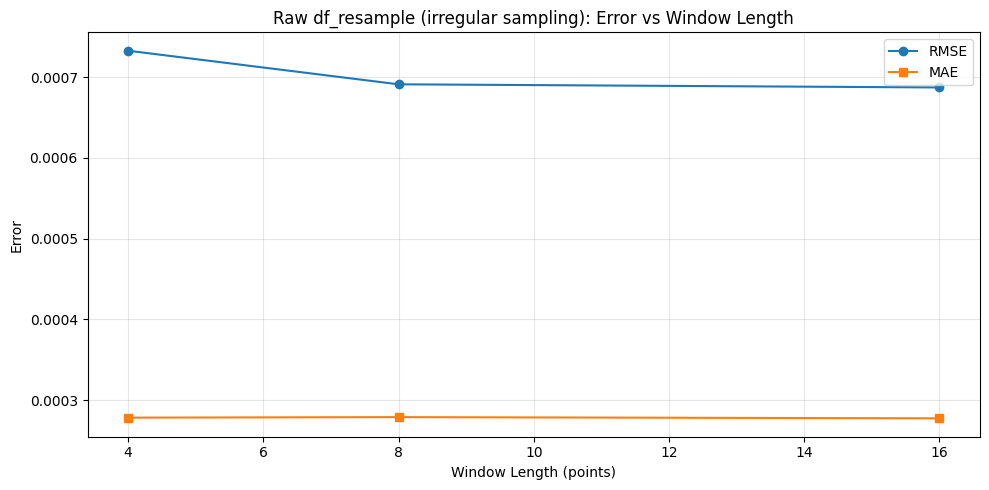

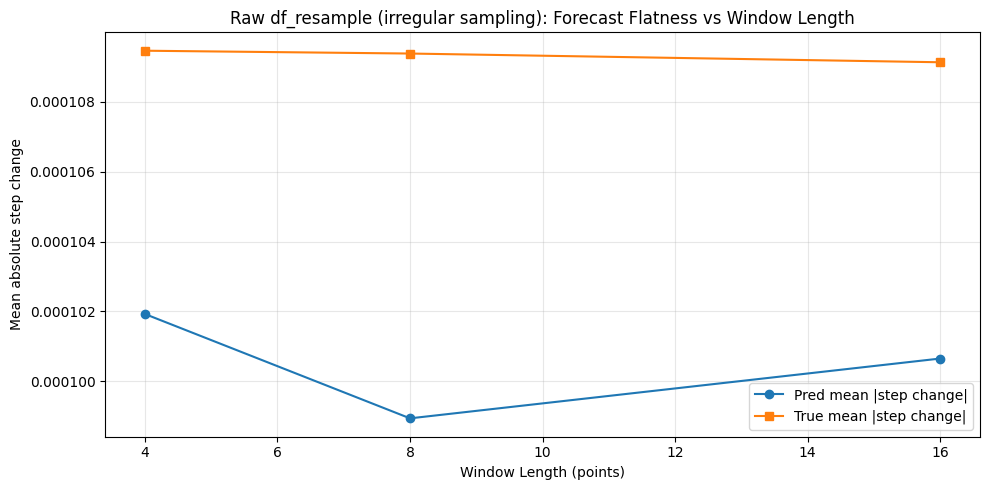

=== 30-minute resampled df_30m interval diagnostics (minutes) ===
count    42927.000000
mean        30.160738
std          2.302087
min         30.000000
50%         30.000000
90%         30.000000
95%         30.000000
max         90.000000
Name: delta_min, dtype: float64

=== Window Sensitivity on 30-minute resampled df_30m ===


,window_size_points,train_rows,test_rows,feature_count,rmse,mae,pred_step_abs_change,true_step_abs_change,flatness_ratio_pred_to_true,pred_std
0,4,34173,8544,10,0.001132,0.000352,0.000181,0.000181,0.998303,0.010732
1,8,33949,8488,14,0.001036,0.000376,0.000175,0.000181,0.967196,0.010538
2,16,33504,8377,22,0.001035,0.000374,0.000170,0.000180,0.942040,0.009970


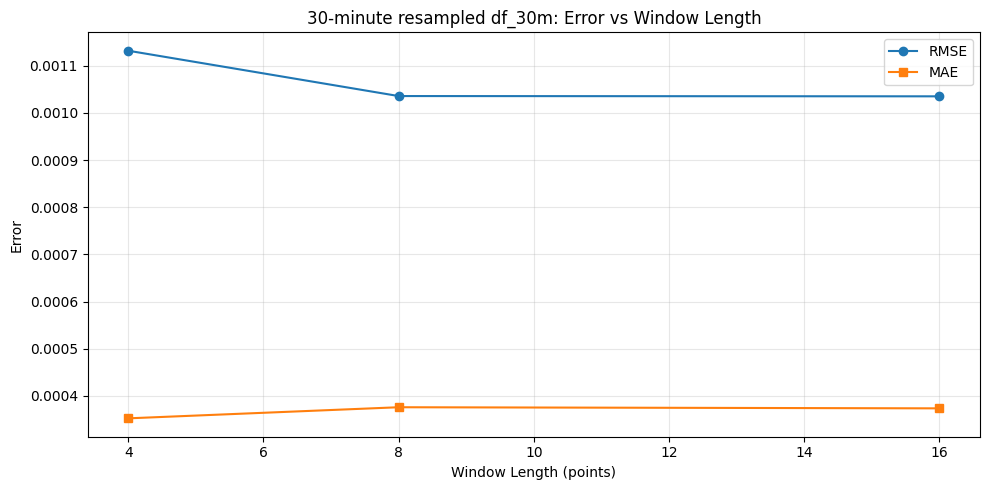

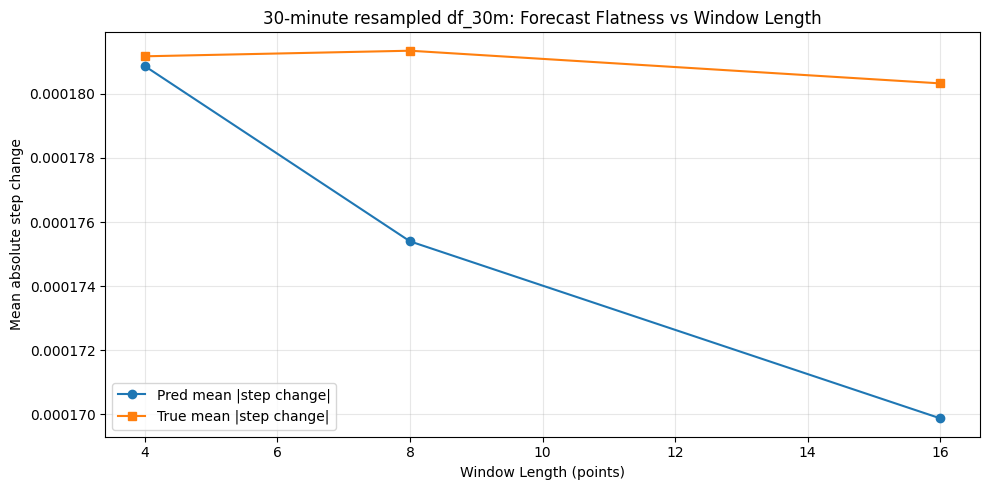

In [9]:
# Sensitivity tests on both datasets:
# 1) df_resample (raw, irregular sampling)
# 2) df_30m (30-minute resampled)

def prepare_dataset_for_sensitivity(df_in):
    df_out = df_in.copy()

    # Ensure datetime is a column for sorting/analysis
    if 'datetime' not in df_out.columns:
        df_out = df_out.reset_index()

    # Normalize column names to match prior pipeline expectations
    rename_map = {}
    if 'event_name' in df_out.columns:
        rename_map['event_name'] = 'Event_name'
    if 'p' in df_out.columns:
        rename_map['p'] = 'price'
    if 't' in df_out.columns and 'timestamp' not in df_out.columns:
        rename_map['t'] = 'timestamp'
    df_out = df_out.rename(columns=rename_map)

    required_cols = ['Event_name', 'category', 'outcome', 'price', 'datetime']
    missing_cols = [c for c in required_cols if c not in df_out.columns]
    if missing_cols:
        raise ValueError(f'Missing required columns in dataset: {missing_cols}')

    df_out['datetime'] = pd.to_datetime(df_out['datetime'])
    df_out = df_out.sort_values(by=['Event_name', 'datetime']).reset_index(drop=True)
    return df_out


def run_window_sensitivity(df_base, window_candidates, dataset_label):
    # Optional diagnostics: sampling interval per event
    interval_df = df_base[['Event_name', 'datetime']].copy()
    interval_df['delta_min'] = interval_df.groupby('Event_name')['datetime'].diff().dt.total_seconds() / 60
    interval_stats = interval_df['delta_min'].dropna().describe(percentiles=[0.5, 0.9, 0.95])
    print(f'=== {dataset_label} interval diagnostics (minutes) ===')
    print(interval_stats)

    results = []

    for ws in window_candidates:
        df_tmp = df_base.copy()
        df_tmp = pd.get_dummies(df_tmp, columns=['category'], drop_first=False)

        for i in range(1, ws + 1):
            df_tmp[f'price_lag_{i}'] = df_tmp.groupby('Event_name')['price'].shift(i)

        df_tmp[f'rolling_mean_{ws}'] = df_tmp.groupby('Event_name')['price'].transform(
            lambda x: x.shift(1).rolling(window=ws).mean()
        )
        df_tmp[f'rolling_std_{ws}'] = df_tmp.groupby('Event_name')['price'].transform(
            lambda x: x.shift(1).rolling(window=ws).std()
        )

        df_tmp = df_tmp.dropna().reset_index(drop=True)

        exclude_cols_tmp = ['Event_name', 'outcome', 'timestamp', 'datetime', 't', 'price', 'market_id']
        feature_cols_tmp = [c for c in df_tmp.columns if c not in exclude_cols_tmp]

        # Keep only model-compatible dtypes (int/float/bool/category)
        X_tmp = df_tmp[feature_cols_tmp].select_dtypes(include=['number', 'bool', 'category'])
        y_tmp = df_tmp['price']

        split_idx_tmp = int(len(df_tmp) * 0.8)
        X_train_tmp, X_test_tmp = X_tmp.iloc[:split_idx_tmp], X_tmp.iloc[split_idx_tmp:]
        y_train_tmp, y_test_tmp = y_tmp.iloc[:split_idx_tmp], y_tmp.iloc[split_idx_tmp:]

        model_tmp = xgb.XGBRegressor(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            objective='reg:squarederror'
        )
        model_tmp.fit(X_train_tmp, y_train_tmp)

        preds_tmp = np.clip(model_tmp.predict(X_test_tmp), 0, 1)

        rmse_tmp = np.sqrt(mean_squared_error(y_test_tmp, preds_tmp))
        mae_tmp = mean_absolute_error(y_test_tmp, preds_tmp)

        pred_step_abs_change = np.mean(np.abs(np.diff(preds_tmp)))
        true_step_abs_change = np.mean(np.abs(np.diff(y_test_tmp.values)))

        results.append({
            'window_size_points': ws,
            'train_rows': len(X_train_tmp),
            'test_rows': len(X_test_tmp),
            'feature_count': X_tmp.shape[1],
            'rmse': rmse_tmp,
            'mae': mae_tmp,
            'pred_step_abs_change': pred_step_abs_change,
            'true_step_abs_change': true_step_abs_change,
            'flatness_ratio_pred_to_true': pred_step_abs_change / true_step_abs_change if true_step_abs_change > 0 else np.nan,
            'pred_std': float(np.std(preds_tmp))
        })

    sensitivity_df = pd.DataFrame(results).sort_values('window_size_points')

    print(f'\n=== Window Sensitivity on {dataset_label} ===')
    display(sensitivity_df)

    plt.figure(figsize=(10, 5))
    plt.plot(sensitivity_df['window_size_points'], sensitivity_df['rmse'], marker='o', label='RMSE')
    plt.plot(sensitivity_df['window_size_points'], sensitivity_df['mae'], marker='s', label='MAE')
    plt.xlabel('Window Length (points)')
    plt.ylabel('Error')
    plt.title(f'{dataset_label}: Error vs Window Length')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(sensitivity_df['window_size_points'], sensitivity_df['pred_step_abs_change'], marker='o', label='Pred mean |step change|')
    plt.plot(sensitivity_df['window_size_points'], sensitivity_df['true_step_abs_change'], marker='s', label='True mean |step change|')
    plt.xlabel('Window Length (points)')
    plt.ylabel('Mean absolute step change')
    plt.title(f'{dataset_label}: Forecast Flatness vs Window Length')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return sensitivity_df


window_candidates = [4, 8, 16]

# 1) Raw df_resample sensitivity (without 30-min averaging)
df_raw = prepare_dataset_for_sensitivity(df_resample)
sensitivity_raw_df = run_window_sensitivity(df_raw, window_candidates, 'Raw df_resample (irregular sampling)')

# 2) 30-minute resampled df sensitivity
df_30m_sens = prepare_dataset_for_sensitivity(df_30m)
sensitivity_30m_df = run_window_sensitivity(df_30m_sens, window_candidates, '30-minute resampled df_30m')

## Step 9: Sudden Price Change Case Study (US X Iran ceasefile by April 7?)
Plot the target event directly to inspect abrupt jumps/drops and compare raw vs 30-minute-smoothed paths.

Selected event for plotting: US x Iran ceasefire by April 7?


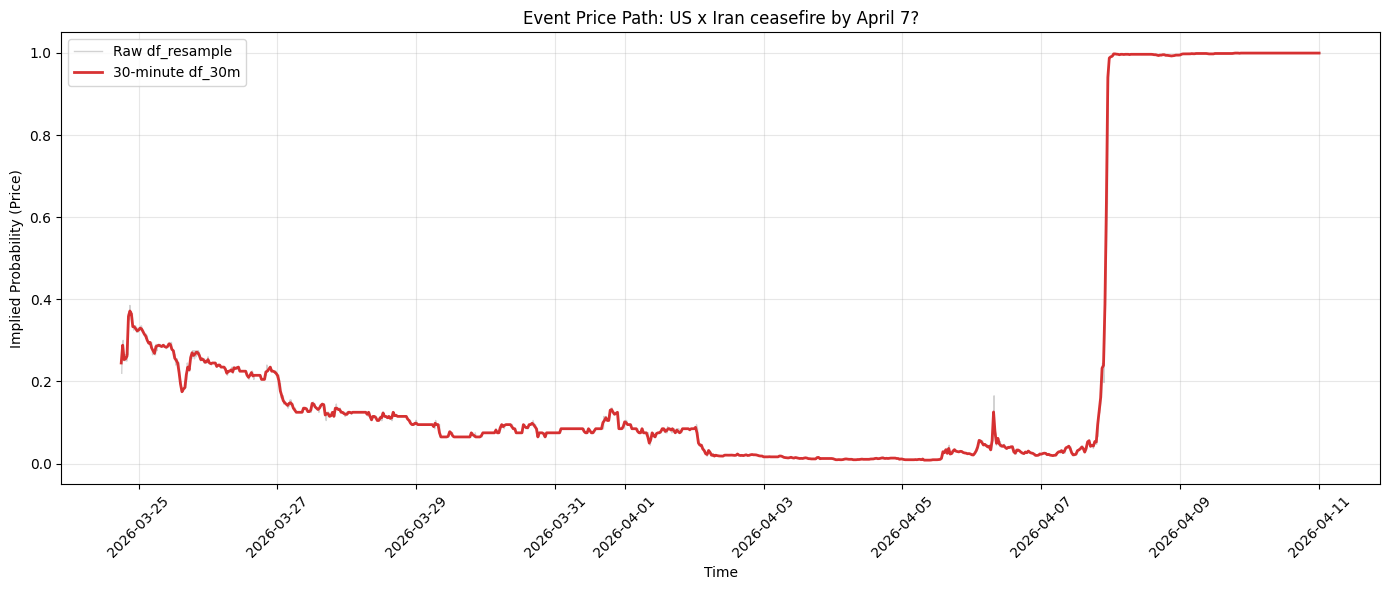

Top 5 absolute step changes (30-minute series):


,datetime,price,abs_step_change
0,2026-04-07 23:00:00,0.940250,0.305750
1,2026-04-07 22:30:00,0.634500,0.247000
2,2026-04-07 22:00:00,0.387500,0.148250
3,2026-03-24 20:30:00,0.358333,0.096667
4,2026-04-07 21:00:00,0.232333,0.072583


In [11]:
import difflib

target_event = 'US X Iran ceasefile by April 7?'

# Helper to standardize source tables to common plotting columns
def standardize_event_df(df_in):
    df_plot = df_in.copy()
    if 'datetime' not in df_plot.columns:
        df_plot = df_plot.reset_index()

    rename_map = {}
    if 'event_name' in df_plot.columns:
        rename_map['event_name'] = 'Event_name'
    if 'p' in df_plot.columns:
        rename_map['p'] = 'price'
    df_plot = df_plot.rename(columns=rename_map)

    required = ['Event_name', 'datetime', 'price']
    missing = [c for c in required if c not in df_plot.columns]
    if missing:
        raise ValueError(f'Missing required columns for plotting: {missing}')

    df_plot['datetime'] = pd.to_datetime(df_plot['datetime'])
    return df_plot


raw_plot_df = standardize_event_df(df_resample)
resampled_plot_df = standardize_event_df(df_30m)

# Build candidate event list from 30-minute table (cleaner reference set)
all_events = sorted(resampled_plot_df['Event_name'].dropna().astype(str).unique())

# 1) Exact match
chosen_event = target_event if target_event in all_events else None

# 2) Case-insensitive exact equivalent
if chosen_event is None:
    lower_to_event = {e.lower(): e for e in all_events}
    chosen_event = lower_to_event.get(target_event.lower())

# 3) Regex-filtered candidates; choose closest string match if multiple
if chosen_event is None:
    fallback_pattern = r'(?i)iran.*april\s*7|april\s*7.*iran|us\s*x\s*iran'
    regex_candidates = [e for e in all_events if pd.Series([e]).str.contains(fallback_pattern, regex=True, na=False).iloc[0]]
    if len(regex_candidates) == 1:
        chosen_event = regex_candidates[0]
    elif len(regex_candidates) > 1:
        close = difflib.get_close_matches(target_event, regex_candidates, n=1, cutoff=0.0)
        chosen_event = close[0] if close else regex_candidates[0]

# 4) Final fallback: closest string match over all events
if chosen_event is None and all_events:
    close = difflib.get_close_matches(target_event, all_events, n=1, cutoff=0.0)
    chosen_event = close[0] if close else None

if chosen_event is None:
    raise ValueError('No event match found in df_30m.')


print(f'Selected event for plotting: {chosen_event}')

raw_event = raw_plot_df[raw_plot_df['Event_name'] == chosen_event].copy()
resampled_event = resampled_plot_df[resampled_plot_df['Event_name'] == chosen_event].copy()

if raw_event.empty and resampled_event.empty:
    raise ValueError(f'No rows found for selected event: {chosen_event}')

plt.figure(figsize=(14, 6))

if not raw_event.empty:
    raw_event = raw_event.sort_values('datetime')
    plt.plot(
        raw_event['datetime'],
        raw_event['price'],
        label='Raw df_resample',
        alpha=0.35,
        linewidth=1.0,
        color='tab:gray'
    )

if not resampled_event.empty:
    resampled_event = resampled_event.sort_values('datetime')
    plt.plot(
        resampled_event['datetime'],
        resampled_event['price'],
        label='30-minute df_30m',
        alpha=0.95,
        linewidth=2.0,
        color='tab:red'
    )

plt.title(f'Event Price Path: {chosen_event}')
plt.xlabel('Time')
plt.ylabel('Implied Probability (Price)')
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

if not resampled_event.empty:
    step_change = resampled_event['price'].diff().abs()
    top_moves = resampled_event.loc[step_change.nlargest(5).index, ['datetime', 'price']].copy()
    top_moves['abs_step_change'] = step_change.loc[top_moves.index].values
    print('Top 5 absolute step changes (30-minute series):')
    display(top_moves.sort_values('abs_step_change', ascending=False).reset_index(drop=True))

## Results Summary

- This notebook tests whether past probability paths alone can predict future market probabilities in Polymarket.
- Based on the model behavior and forecast plots, **historical price features by themselves are often insufficient** for reliable forward prediction.
- Many events show sudden jumps or drops that are not well explained by recent price history, suggesting dependence on external factors (for example: breaking news, new information releases, liquidity shocks, or strategic trading behavior).
- In periods without major information shocks, forecasts tend to stay relatively close to recent levels, and observed short-horizon deviations are often modest.
- Taken together, these findings suggest that time-series history is useful as a baseline signal, but not enough on its own for robust prediction across diverse events.

Project-level implication: for Polymarket, stronger forecasting likely requires adding exogenous/contextual features (news and event metadata, volume/liquidity signals, and market microstructure indicators) rather than relying only on lagged prices.